In [1]:
import open_clip
import torch
from PIL import Image
from matplotlib import pyplot as plt

from homework_3.functions import parse_img, get_cache, api_response_to_tensor
from homework_3.classes import ClipModel

/home/Baldi/Projects/PycharmProjects/uni-MultiModal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MIOpen: Warning [ParseAndLoadDb] File is unreadable: "/home/Baldi/Projects/PycharmProjects/uni-MultiModal/.venv/lib/python3.13/site-packages/_rocm_sdk_libraries/share/miopen/db/gfx110054.HIP.fdb.txt"


Image black.png
Hash: fc3f2e563bba4bc8612ea520b79a8b60
API results:	tensor([0.6755, 0.3245, 0.9545, 0.0455])
Model results:	tensor([[8.8651e-01, 1.1349e-01, 9.9903e-01, 9.6654e-04]], device='cuda:0',
       grad_fn=<CatBackward0>)


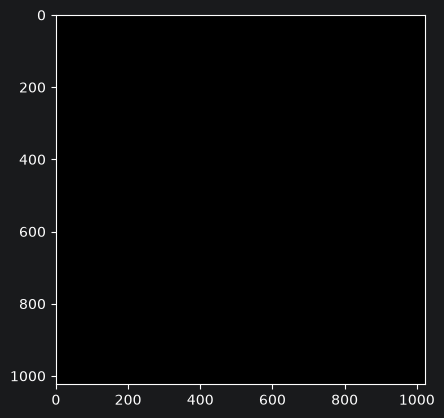

In [2]:
WEIGHTS_HEAD1 = "../weights/concept1_25_2.pth"
WEIGHTS_HEAD2 = "../weights/concept2_25_2.pth"

IMG_DIR = "../img"

clip_model = ClipModel(WEIGHTS_HEAD1, WEIGHTS_HEAD2)

In [2]:
image_file = "black.png"

try:
    raw_img = Image.open(f"{IMG_DIR}/{image_file}")
except FileNotFoundError:
    exit("File not found")

_, img_hash = parse_img(raw_img)
api_response = get_cache(img_hash)
# We are only testing results from cache here
# noinspection bad-argument-type
label = api_response_to_tensor(api_response)
preprocessed_image = clip_model.preprocess(raw_img).unsqueeze(0).cuda()

output = clip_model(preprocessed_image)

plt.imshow(raw_img)

print(f"Image {image_file}\n"
      f"Hash: {img_hash}\n"
      f"API results:\t{label}\n"
      f"Model results:\t{output}")